# 01 — Exploration de la charge des archivistes

Objectif : comprendre la série avant de la modéliser. À la fin de ce notebook, on doit pouvoir expliquer
chaque pic et chaque creux de la charge par site, et savoir quelles informations donner à Prophet.

Données : CSV générés par `generate_dataset.py` (simulés, voir `README.md`).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA = Path("data") if Path("data").exists() else Path("../data")  # racine du projet ou dossier notebooks/
plt.rcParams.update({"figure.figsize": (13, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

dim_date   = pd.read_csv(DATA / "dim_date.csv", parse_dates=["date"])
dim_site   = pd.read_csv(DATA / "dim_site.csv")
dim_client = pd.read_csv(DATA / "dim_client.csv", parse_dates=["date_debut_contrat", "date_fin_contrat"])
dim_type   = pd.read_csv(DATA / "dim_type_mouvement.csv")
dim_evt    = pd.read_csv(DATA / "dim_evenement.csv", parse_dates=["date_debut", "date_fin"])
mouv       = pd.read_csv(DATA / "fact_mouvement.csv", parse_dates=["date"])
charge     = pd.read_csv(DATA / "fact_charge_jour.csv", parse_dates=["date"])
stock      = pd.read_csv(DATA / "fact_stock_mensuel.csv", parse_dates=["date_fin_mois"])

NOMS_SITES = dim_site.set_index("site_id")["ville"].to_dict()
charge = charge.merge(dim_date[["date", "est_ouvre", "est_pont", "jour_ferie", "nom_jour", "mois", "annee"]], on="date")
ouvre = charge[charge.est_ouvre].copy()   # la cible n'a de sens que les jours ouvrés

## 1. Contrôles de qualité

Avant d'analyser quoi que ce soit : volumes, période, valeurs manquantes, clés orphelines.

In [2]:
tables = {"dim_date": dim_date, "dim_site": dim_site, "dim_client": dim_client, "dim_type": dim_type,
          "dim_evenement": dim_evt, "fact_mouvement": mouv, "fact_charge_jour": charge, "fact_stock": stock}
pd.DataFrame({n: {"lignes": len(t), "colonnes": t.shape[1], "valeurs_nulles": int(t.isna().sum().sum())}
              for n, t in tables.items()}).T

,lignes,colonnes,valeurs_nulles
dim_date,2129,12,3844
dim_site,5,9,0
dim_client,505,13,953
dim_type,6,4,0
dim_evenement,519,9,482
fact_mouvement,381071,7,0
fact_charge_jour,10645,18,13620
fact_stock,35350,4,0


In [3]:
controles = {
    "Période des mouvements": f"{mouv.date.min():%d/%m/%Y} → {mouv.date.max():%d/%m/%Y}",
    "Clients des mouvements absents de dim_client": (~mouv.client_id.isin(dim_client.client_id)).sum(),
    "Types de mouvement inconnus": (~mouv.type_mouvement.isin(dim_type.type_mouvement)).sum(),
    "Mouvements un jour non ouvré": mouv.merge(dim_date[["date", "est_ouvre"]]).query("not est_ouvre").shape[0],
    "Doublons (date, client, type)": mouv.duplicated(["date", "client_id", "type_mouvement"]).sum(),
    "Stocks négatifs": (stock.stock_boites < 0).sum(),
    "Charge > 0 un jour non ouvré": charge.query("not est_ouvre and heures_requises > 0").shape[0],
}
pd.Series(controles, name="résultat").to_frame()

,résultat
Période des mouvements,04/01/2021 → 30/10/2026
Clients des mouvements absents de dim_client,0
Types de mouvement inconnus,0
Mouvements un jour non ouvré,0
"Doublons (date, client, type)",0
Stocks négatifs,0
Charge > 0 un jour non ouvré,0


Les valeurs nulles attendues : `date_fin_contrat` (clients toujours actifs), `evenement_id`,
`nb_boites` pour les pics d'audit, `taux_charge` les jours non ouvrés.

## 2. La cible : heures requises par site

Vue hebdomadaire, plus lisible que le jour pour repérer les tendances et les événements.

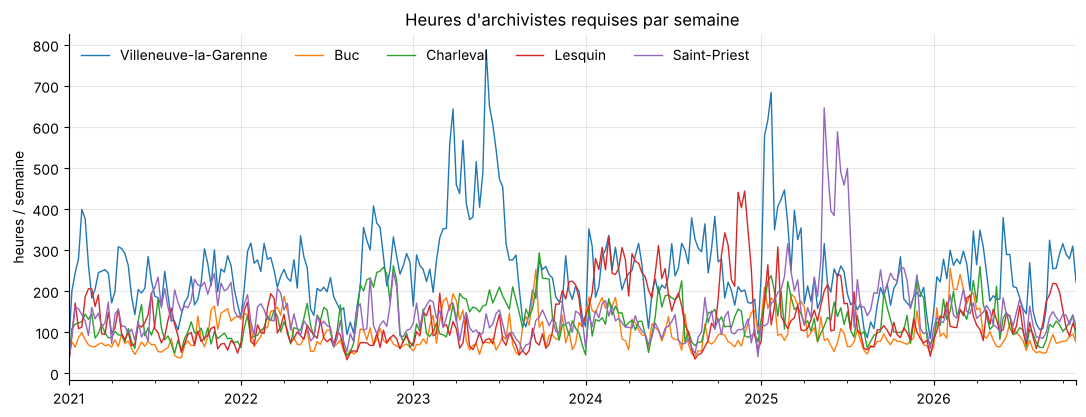

In [4]:
hebdo = (ouvre.groupby([pd.Grouper(key="date", freq="W-MON"), "site_id"]).heures_requises.sum()
         .unstack().rename(columns=NOMS_SITES))
ax = hebdo.plot(lw=1)
ax.set(title="Heures d'archivistes requises par semaine", xlabel="", ylabel="heures / semaine")
ax.legend(ncol=5, loc="upper left", frameon=False)
plt.show()

In [5]:
ouvre.groupby(["annee", "site_id"]).heures_requises.mean().unstack().rename(columns=NOMS_SITES).round(1)

site_id,Villeneuve-la-Garenne,Buc,Charleval,Lesquin,Saint-Priest
annee,,,,,
2021,45.7,17.1,20.2,22.0,32.2
2022,50.0,18.7,27.9,19.1,26.4
2023,67.1,21.7,30.7,22.9,25.5
2024,51.6,21.8,26.6,44.9,23.4
2025,50.9,20.6,27.9,26.4,49.0
2026,49.9,22.5,26.5,27.2,28.4


**Mes observations :**
<!-- À compléter : niveau de chaque site, tendance générale, pics visibles et leur durée. -->

## 3. De quoi est faite la charge

Répartition mensuelle par type de mouvement, tous sites confondus.

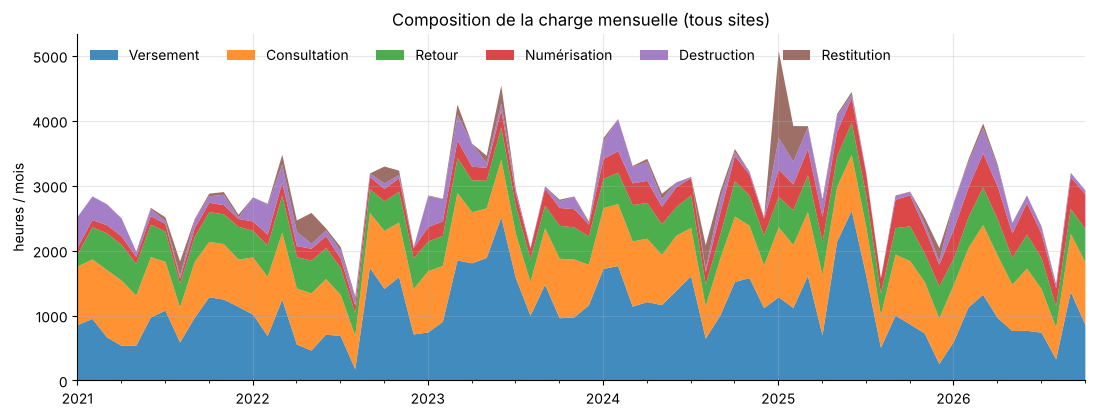

,% de la charge totale
Versement,38.0
Consultation,28.5
Retour,15.7
Numérisation,9.2
Destruction,5.9
Restitution,2.7


In [6]:
cols = {"heures_versement": "Versement", "heures_consultation": "Consultation", "heures_retour": "Retour",
        "heures_numerisation": "Numérisation", "heures_destruction": "Destruction", "heures_restitution": "Restitution"}
mensuel = ouvre.groupby(pd.Grouper(key="date", freq="MS"))[list(cols)].sum().rename(columns=cols)
ax = mensuel.plot.area(lw=0, alpha=0.85)
ax.set(title="Composition de la charge mensuelle (tous sites)", xlabel="", ylabel="heures / mois")
ax.legend(ncol=6, loc="upper left", frameon=False)
plt.show()

(mensuel.sum() / mensuel.sum().sum() * 100).round(1).rename("% de la charge totale").to_frame()

In [7]:
# Part de la numérisation dans les demandes de consultation, par an
dem = mouv[mouv.type_mouvement.isin(["CON", "NUM"])].groupby([mouv.date.dt.year, "type_mouvement"]).nb_boites.sum().unstack()
(dem["NUM"] / dem.sum(axis=1) * 100).round(1).rename("% des demandes servies en numérique").to_frame()

,% des demandes servies en numérique
date,
2021,9.7
2022,13.5
2023,17.3
2024,21.4
2025,24.9
2026,28.2


**Mes observations :**
<!-- À compléter : quel type pèse le plus, lequel est le plus irrégulier, la bascule vers le numérique. -->

## 4. Saisonnalités

### Jour de la semaine

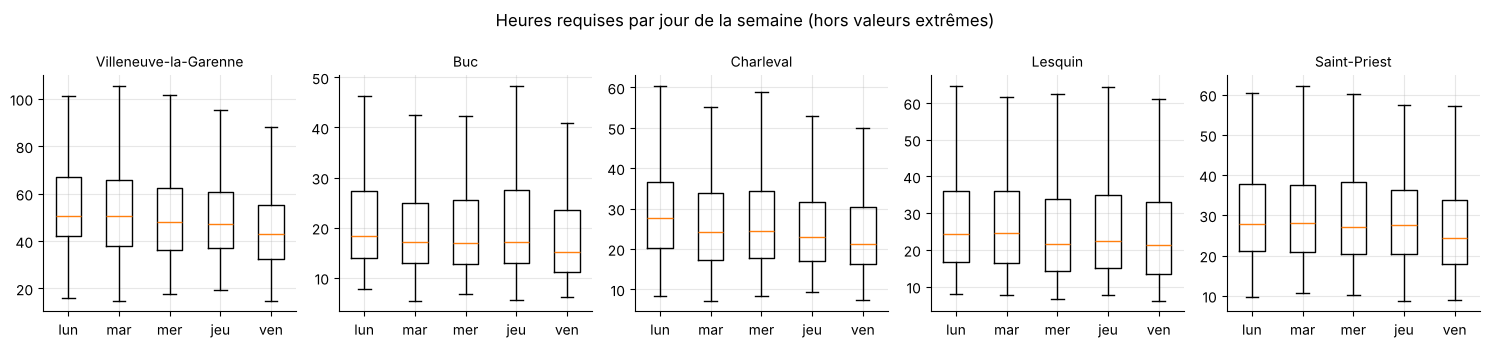

nom_jour,lundi,mardi,mercredi,jeudi,vendredi
site_id,,,,,
Villeneuve-la-Garenne,1.07,1.04,1.00,0.99,0.91
Buc,1.06,1.00,1.01,1.01,0.92
Charleval,1.11,0.99,1.01,0.96,0.93
Lesquin,1.04,1.05,0.95,1.00,0.95
Saint-Priest,1.03,1.02,1.03,1.00,0.92


In [8]:
ordre = ["lundi", "mardi", "mercredi", "jeudi", "vendredi"]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), sharey=False)
for ax, (site, g) in zip(axes, ouvre.groupby("site_id")):
    ax.boxplot([g[g.nom_jour == j].heures_requises for j in ordre], showfliers=False)
    ax.set_xticks(range(1, 6), [j[:3] for j in ordre])
    ax.set_title(NOMS_SITES[site], fontsize=10)
fig.suptitle("Heures requises par jour de la semaine (hors valeurs extrêmes)")
plt.tight_layout(); plt.show()

# Indice : moyenne du jour / moyenne de la semaine
idx = ouvre.groupby(["site_id", "nom_jour"]).heures_requises.mean().unstack()[ordre]
(idx.div(idx.mean(axis=1), axis=0)).rename(index=NOMS_SITES).round(2)

### Mois de l'année

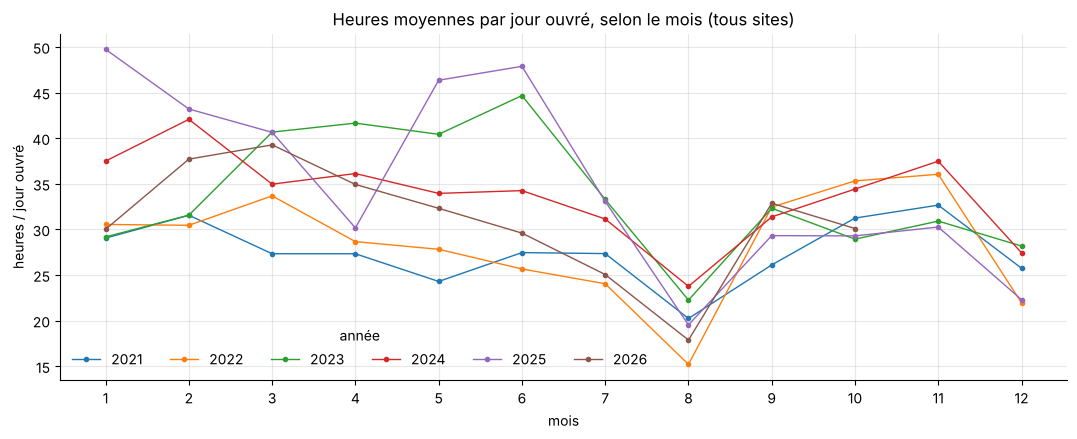

In [9]:
profil = ouvre.groupby(["annee", "mois"]).heures_requises.mean().unstack(0)
ax = profil.plot(marker="o", lw=1, ms=3)
ax.set(title="Heures moyennes par jour ouvré, selon le mois (tous sites)", xlabel="mois",
       ylabel="heures / jour ouvré", xticks=range(1, 13))
ax.legend(title="année", ncol=6, frameon=False)
plt.show()

### Jours fériés et ponts

In [10]:
effet_pont = ouvre.groupby(["site_id", "est_pont"]).heures_requises.mean().unstack()
effet_pont.columns = ["jour normal", "pont"]
effet_pont["écart %"] = ((effet_pont["pont"] / effet_pont["jour normal"] - 1) * 100).round(1)
effet_pont.rename(index=NOMS_SITES).round(1)

,jour normal,pont,écart %
site_id,,,
Villeneuve-la-Garenne,52.7,41.9,-20.5
Buc,20.4,14.3,-30.0
Charleval,26.7,24.1,-9.5
Lesquin,27.2,20.7,-24.0
Saint-Priest,30.9,30.2,-2.4


In [11]:
# Lendemain de férié : les demandes du jour férié se reportent-elles ?
dd = dim_date.copy()
dd["veille_ferie"] = dd.est_ferie.shift(1, fill_value=False)
lendemain = ouvre.merge(dd[["date", "veille_ferie"]]).groupby("veille_ferie").heures_requises.mean()
lendemain.rename({False: "jour ouvré normal", True: "lendemain de férié"}).round(1).to_frame()

,heures_requises
veille_ferie,
jour ouvré normal,31.6
lendemain de férié,30.4


**Mes observations :**
<!-- À compléter : force de l'effet lundi, profondeur du creux d'août, effet des ponts. -->

## 5. Les événements

Deux familles très différentes pour la modélisation :
- **connus à l'avance** (reprises de fonds, arrivées de clients, départs) : utilisables comme régresseurs ;
- **imprévus** (contrôles, audits, contentieux) : ils font partie du bruit, on ne peut pas les donner au modèle.

In [12]:
dim_evt.groupby(["type_evenement", "connu_a_lavance"]).agg(
    nb=("evenement_id", "count"), boites=("nb_boites", "sum"),
    duree_moy_jours=("date_fin", lambda s: (s - dim_evt.loc[s.index, "date_debut"]).dt.days.mean().round(0)))

,,nb,boites,duree_moy_jours
type_evenement,connu_a_lavance,,,
Arrivée nouveau client,True,31,294027.0,67.0
Départ client (restitution),True,1,20000.0,46.0
Pic de consultations,False,482,0.0,18.0
Reprise de fonds,True,5,127000.0,77.0


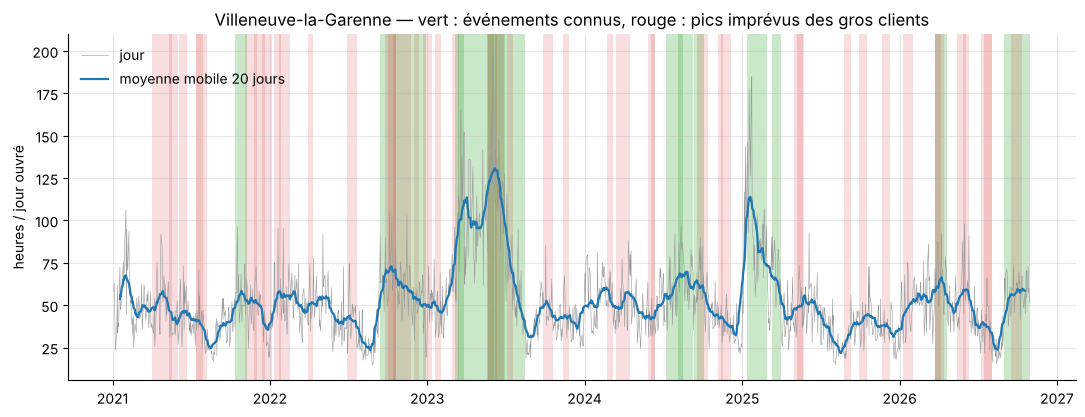

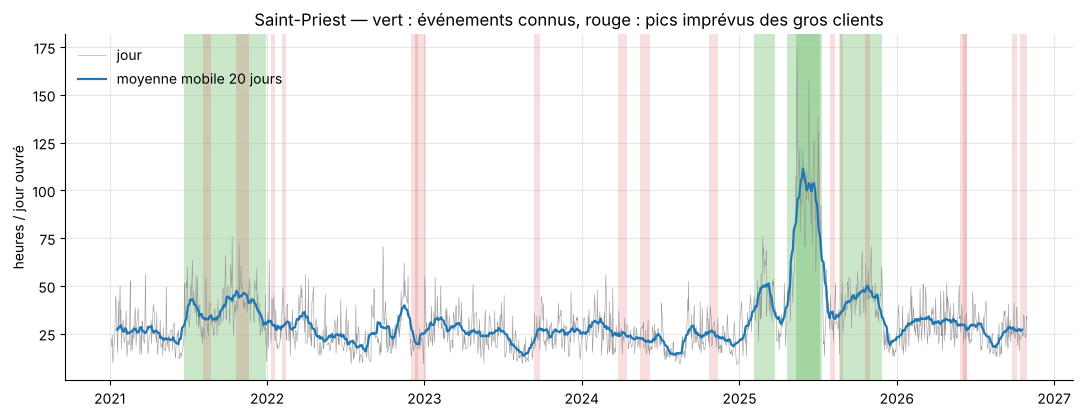

In [13]:
def tracer_site(site):
    s = ouvre[ouvre.site_id == site].set_index("date").heures_requises
    fig, ax = plt.subplots()
    ax.plot(s.index, s, lw=0.4, color="0.6", label="jour")
    ax.plot(s.rolling(20, center=True).mean(), lw=1.6, color="C0", label="moyenne mobile 20 jours")
    # Pics imprévus : on n'affiche que ceux des gros clients (>= 3 000 boîtes), sinon le graphique est illisible
    gros = dim_client.loc[dim_client.stock_cible_boites >= 3000, "client_id"]
    evts = dim_evt[(dim_evt.site_id == site) & (dim_evt.connu_a_lavance | dim_evt.client_id.isin(gros))]
    for _, e in evts.iterrows():
        couleur = "C2" if e.connu_a_lavance else "C3"
        alpha = 0.25 if e.connu_a_lavance else 0.15
        ax.axvspan(e.date_debut, e.date_fin, color=couleur, alpha=alpha, lw=0)
    ax.set(title=f"{NOMS_SITES[site]} — vert : événements connus, rouge : pics imprévus des gros clients",
           ylabel="heures / jour ouvré")
    ax.legend(frameon=False, loc="upper left")
    plt.show()

for site in ["S01", "S05"]:
    tracer_site(site)

In [14]:
# Poids des événements connus dans la charge : jours couverts vs non couverts
connus = dim_evt[dim_evt.connu_a_lavance]
ouvre["evt_connu"] = False
for _, e in connus.iterrows():
    m = (ouvre.site_id == e.site_id) & ouvre.date.between(e.date_debut, e.date_fin)
    ouvre.loc[m, "evt_connu"] = True
ouvre.groupby(["site_id", "evt_connu"]).heures_requises.mean().unstack().rename(
    index=NOMS_SITES, columns={False: "sans événement", True: "pendant un événement connu"}).round(1)

evt_connu,sans événement,pendant un événement connu
site_id,,
Villeneuve-la-Garenne,44.7,74.7
Buc,16.7,34.3
Charleval,24.0,40.7
Lesquin,21.1,47.6
Saint-Priest,25.9,50.8


**Mes observations :**
<!-- À compléter : quels événements se voient le plus, et si les pics imprévus sont visibles au niveau site. -->

## 6. Charge vs capacité

Le taux de charge = heures requises / heures disponibles des archivistes du site.

In [15]:
ouvre["surcharge"] = ouvre.taux_charge > 1.10
tab = ouvre.groupby(["annee", "site_id"]).surcharge.mean().unstack().rename(columns=NOMS_SITES)
(tab * 100).round(0).astype(int).astype(str) + " %"

site_id,Villeneuve-la-Garenne,Buc,Charleval,Lesquin,Saint-Priest
annee,,,,,
2021,25 %,29 %,24 %,30 %,35 %
2022,36 %,32 %,50 %,15 %,17 %
2023,43 %,39 %,39 %,37 %,16 %
2024,10 %,25 %,13 %,76 %,18 %
2025,24 %,22 %,26 %,4 %,82 %
2026,23 %,24 %,19 %,23 %,0 %


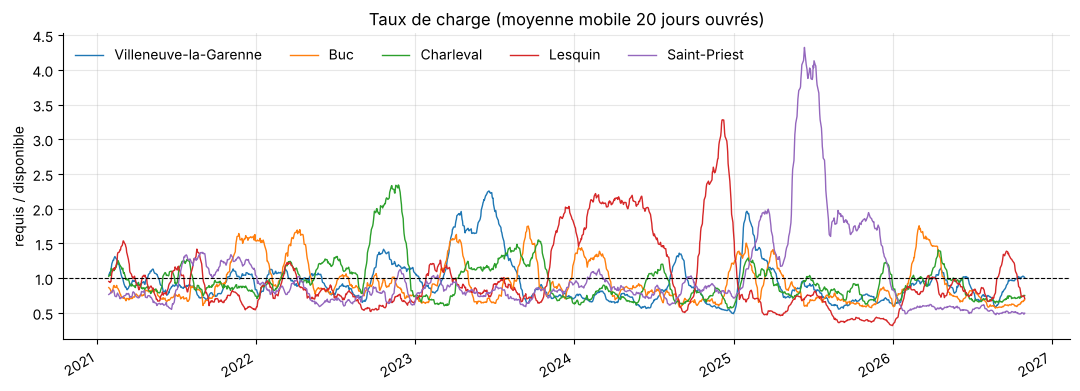

In [16]:
ax = ouvre.pivot_table(index="date", columns="site_id", values="taux_charge").rolling(20).mean() \
          .rename(columns=NOMS_SITES).plot(lw=1)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set(title="Taux de charge (moyenne mobile 20 jours ouvrés)", xlabel="", ylabel="requis / disponible")
ax.legend(ncol=5, frameon=False, loc="upper left")
plt.show()

C'est ici que le forecast prend son sens : une prévision fiable de la charge permet d'anticiper
les périodes au-dessus de 1 (renfort, intérim) et celles nettement en dessous (congés, formation).

**Mes observations :**
<!-- À compléter -->

## 7. Clients et segments

In [17]:
# Concentration : part du stock détenue par les plus gros clients
dernier = stock[stock.date_fin_mois == stock.date_fin_mois.max()].sort_values("stock_boites", ascending=False)
cumul = dernier.stock_boites.cumsum() / dernier.stock_boites.sum()
print(f"Les 10 % de clients les plus gros détiennent {cumul.iloc[int(len(cumul)*0.1)]:.0%} du stock")
print(f"Les 20 % de clients les plus gros détiennent {cumul.iloc[int(len(cumul)*0.2)]:.0%} du stock")

Les 10 % de clients les plus gros détiennent 55% du stock
Les 20 % de clients les plus gros détiennent 72% du stock


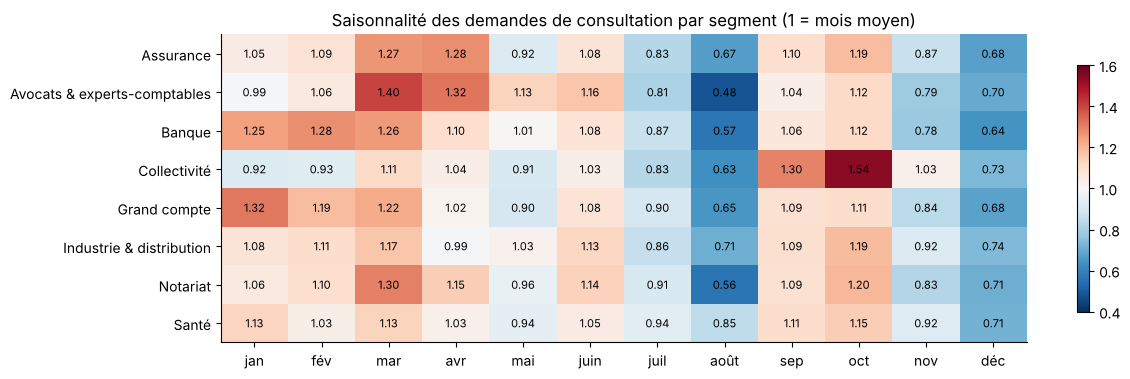

In [18]:
seg = mouv.merge(dim_client[["client_id", "segment"]])
heat = (seg[seg.type_mouvement.isin(["CON", "NUM"])]
        .groupby(["segment", seg.date.dt.month]).nb_boites.sum().unstack())
heat = heat.div(heat.mean(axis=1), axis=0)   # indice 1 = mois moyen du segment
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(heat, cmap="RdBu_r", vmin=0.4, vmax=1.6, aspect="auto")
ax.set_xticks(range(12), ["jan", "fév", "mar", "avr", "mai", "juin", "juil", "août", "sep", "oct", "nov", "déc"])
ax.set_yticks(range(len(heat)), heat.index)
for i in range(heat.shape[0]):
    for j in range(12):
        ax.text(j, i, f"{heat.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Saisonnalité des demandes de consultation par segment (1 = mois moyen)")
ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8); plt.show()

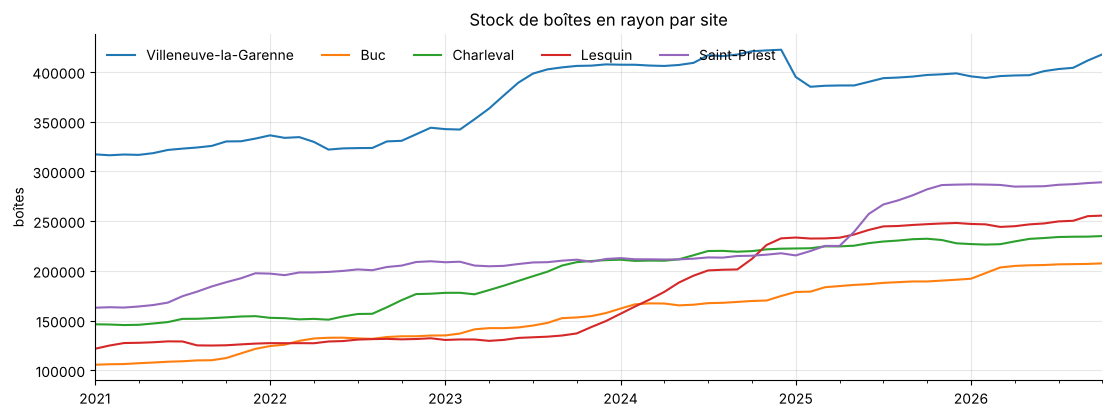

In [19]:
ax = stock.groupby(["date_fin_mois", "site_id"]).stock_boites.sum().unstack().rename(columns=NOMS_SITES).plot(lw=1.5)
ax.set(title="Stock de boîtes en rayon par site", xlabel="", ylabel="boîtes")
ax.legend(ncol=5, frameon=False, loc="upper left")
plt.show()

**Mes observations :**
<!-- À compléter -->

## 8. Ce qu'on retient pour la modélisation

<!-- À rédiger avec tes propres mots une fois les cellules exécutées. Pistes à trancher :
- un modèle par site ou un modèle global ?
- prévoir au jour ou à la semaine ?
- quels événements passer en régresseur, comment encoder leur intensité ?
- que faire des pics imprévus (les laisser, les écrêter, les modéliser à part) ?
- quelle période de test, quel horizon de prévision utile pour un responsable de site ?
-->